# K-NEAREST NEIGHBORS (K-NN) & LINEAR REGRESSION
**Họ và tên sinh viên**: Nguyễn Hải Anh
**Mã số sinh viên (MSSV)**: 24001968

---
Tập notebook này trình bày lời giải và kết quả thực nghiệm cho các bài tập trong hướng dẫn:
- **Bài tập B.1**: Hồi quy tuyến tính trên tập dữ liệu `fuel.txt` (đánh giá MSE, MAE, R2).
- **Bài tập tự thực hành 1 (Ví dụ B.3)**: Hồi quy tuyến tính & K-NN trên tập dữ liệu `SAT_GPA.csv`.
- **Bài tập 2 (Ví dụ B.4)**: Hồi quy đa biến trên `vidu4_lin_reg.txt` (độ dày NTM).
- **Bài tập 3 (Ví dụ B.5)**: Hồi quy và K-NN (K=18) trên `real_estate.csv`.


In [ ]:
import math
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Tự động tìm thư mục chứa dữ liệu guide bất kể bạn chạy notebook từ đâu
POSSIBLE_DIRS = [
    os.path.abspath(os.path.join(os.getcwd(), 'Week1', 'guide')),
    os.path.abspath(os.path.join(os.getcwd(), '..', 'guide')),
    os.path.abspath(os.path.join(os.getcwd(), 'guide')),
    r'd:\MachineLearning\Week1\guide'
]
GUIDE_DIR = next((d for d in POSSIBLE_DIRS if os.path.exists(d)), r'd:\MachineLearning\Week1\guide')

print('Đã import thành công các thư viện cần thiết!')
print('Thư mục dữ liệu đã tìm thấy:', GUIDE_DIR)


Đã import thành công các thư viện cần thiết!
Thư mục dữ liệu đã tìm thấy: D:\MachineLearning\Week1\guide


## 1. BÀI TẬP B.1: Hồi quy tuyến tính mức độ tiêu thụ nhiên liệu (`fuel.txt`)
- Tập huấn luyện: 40 mẫu đầu.
- Tập kiểm thử: 11 mẫu sau.
- Đánh giá mô hình bằng MSE, MAE, R-square trên cả hai tập.

In [ ]:
data_path = os.path.join(GUIDE_DIR, 'fuel.txt')
with open(data_path, 'r', encoding='utf-8') as f:
    lines = f.readlines()
lines.pop(0) # Bỏ tiêu đề

x_data, y_data = [], []
for line in lines:
    s = line.replace('\n', '').replace('"', '').split(',')
    drivers, fuelc, income = float(s[1]), float(s[2]), float(s[3])
    miles, pop, tax = float(s[4]), float(s[6]), float(s[7])
    
    fuel = 1000 * fuelc / pop
    dlic = 1000 * drivers / pop
    logMiles = math.log2(miles)
    
    y_data.append(fuel)
    x_data.append([tax, dlic, income, logMiles])

X_f = np.array(x_data)
y_f = np.array(y_data)

X_train_f, y_train_f = X_f[:40], y_f[:40]
X_val_f, y_val_f = X_f[40:], y_f[40:]

model_fuel = LinearRegression()
model_fuel.fit(X_train_f, y_train_f)

pred_train_f = model_fuel.predict(X_train_f)
pred_val_f = model_fuel.predict(X_val_f)

print(f'Hệ số chặn (w0): {model_fuel.intercept_:.4f}')
print(f'Các trọng số [Tax, Dlic, Income, logMiles]: {model_fuel.coef_}')
print('\nĐánh giá trên tập Training (40 mẫu):')
print(f' - MSE: {mean_squared_error(y_train_f, pred_train_f):.4f}')
print(f' - MAE: {mean_absolute_error(y_train_f, pred_train_f):.4f}')
print(f' - R2 : {r2_score(y_train_f, pred_train_f):.4f}')

print('\nĐánh giá trên tập Validation (11 mẫu):')
print(f' - MSE: {mean_squared_error(y_val_f, pred_val_f):.4f}')
print(f' - MAE: {mean_absolute_error(y_val_f, pred_val_f):.4f}')
print(f' - R2 : {r2_score(y_val_f, pred_val_f):.4f}')

Hệ số chặn (w0): 135.1420
Các trọng số [Tax, Dlic, Income, logMiles]: [-1.90301193e+00  4.18592399e-01 -6.22943009e-03  1.95938559e+01]

Đánh giá trên tập Training (40 mẫu):
 - MSE: 3344.7858
 - MAE: 44.2097
 - R2 : 0.5516

Đánh giá trên tập Validation (11 mẫu):
 - MSE: 6253.3626
 - MAE: 60.6155
 - R2 : -0.0242


## 2. BÀI TẬP TỰ THỰC HÀNH 1 (VÍ DỤ B.3): SAT và GPA
- Hệ số tương quan Pearson.
- Hồi quy tuyến tính (64 train / 20 val).
- Vẽ đồ thị đường hồi quy.
- So sánh với K-NN (k = 8).

(i) Hệ số tương quan Pearson giữa SAT và GPA: 0.63718
(iii) Phương trình hồi quy: GPA = 0.838210 + 0.001318 * SAT
(iv & v) So sánh kết quả trên tập Validation:
Linear Regression -> MSE: 0.072638, MAE: 0.248804, R2: -9.667975
K-NN (k = 8)      -> MSE: 0.081378, MAE: 0.271188, R2: -10.951519


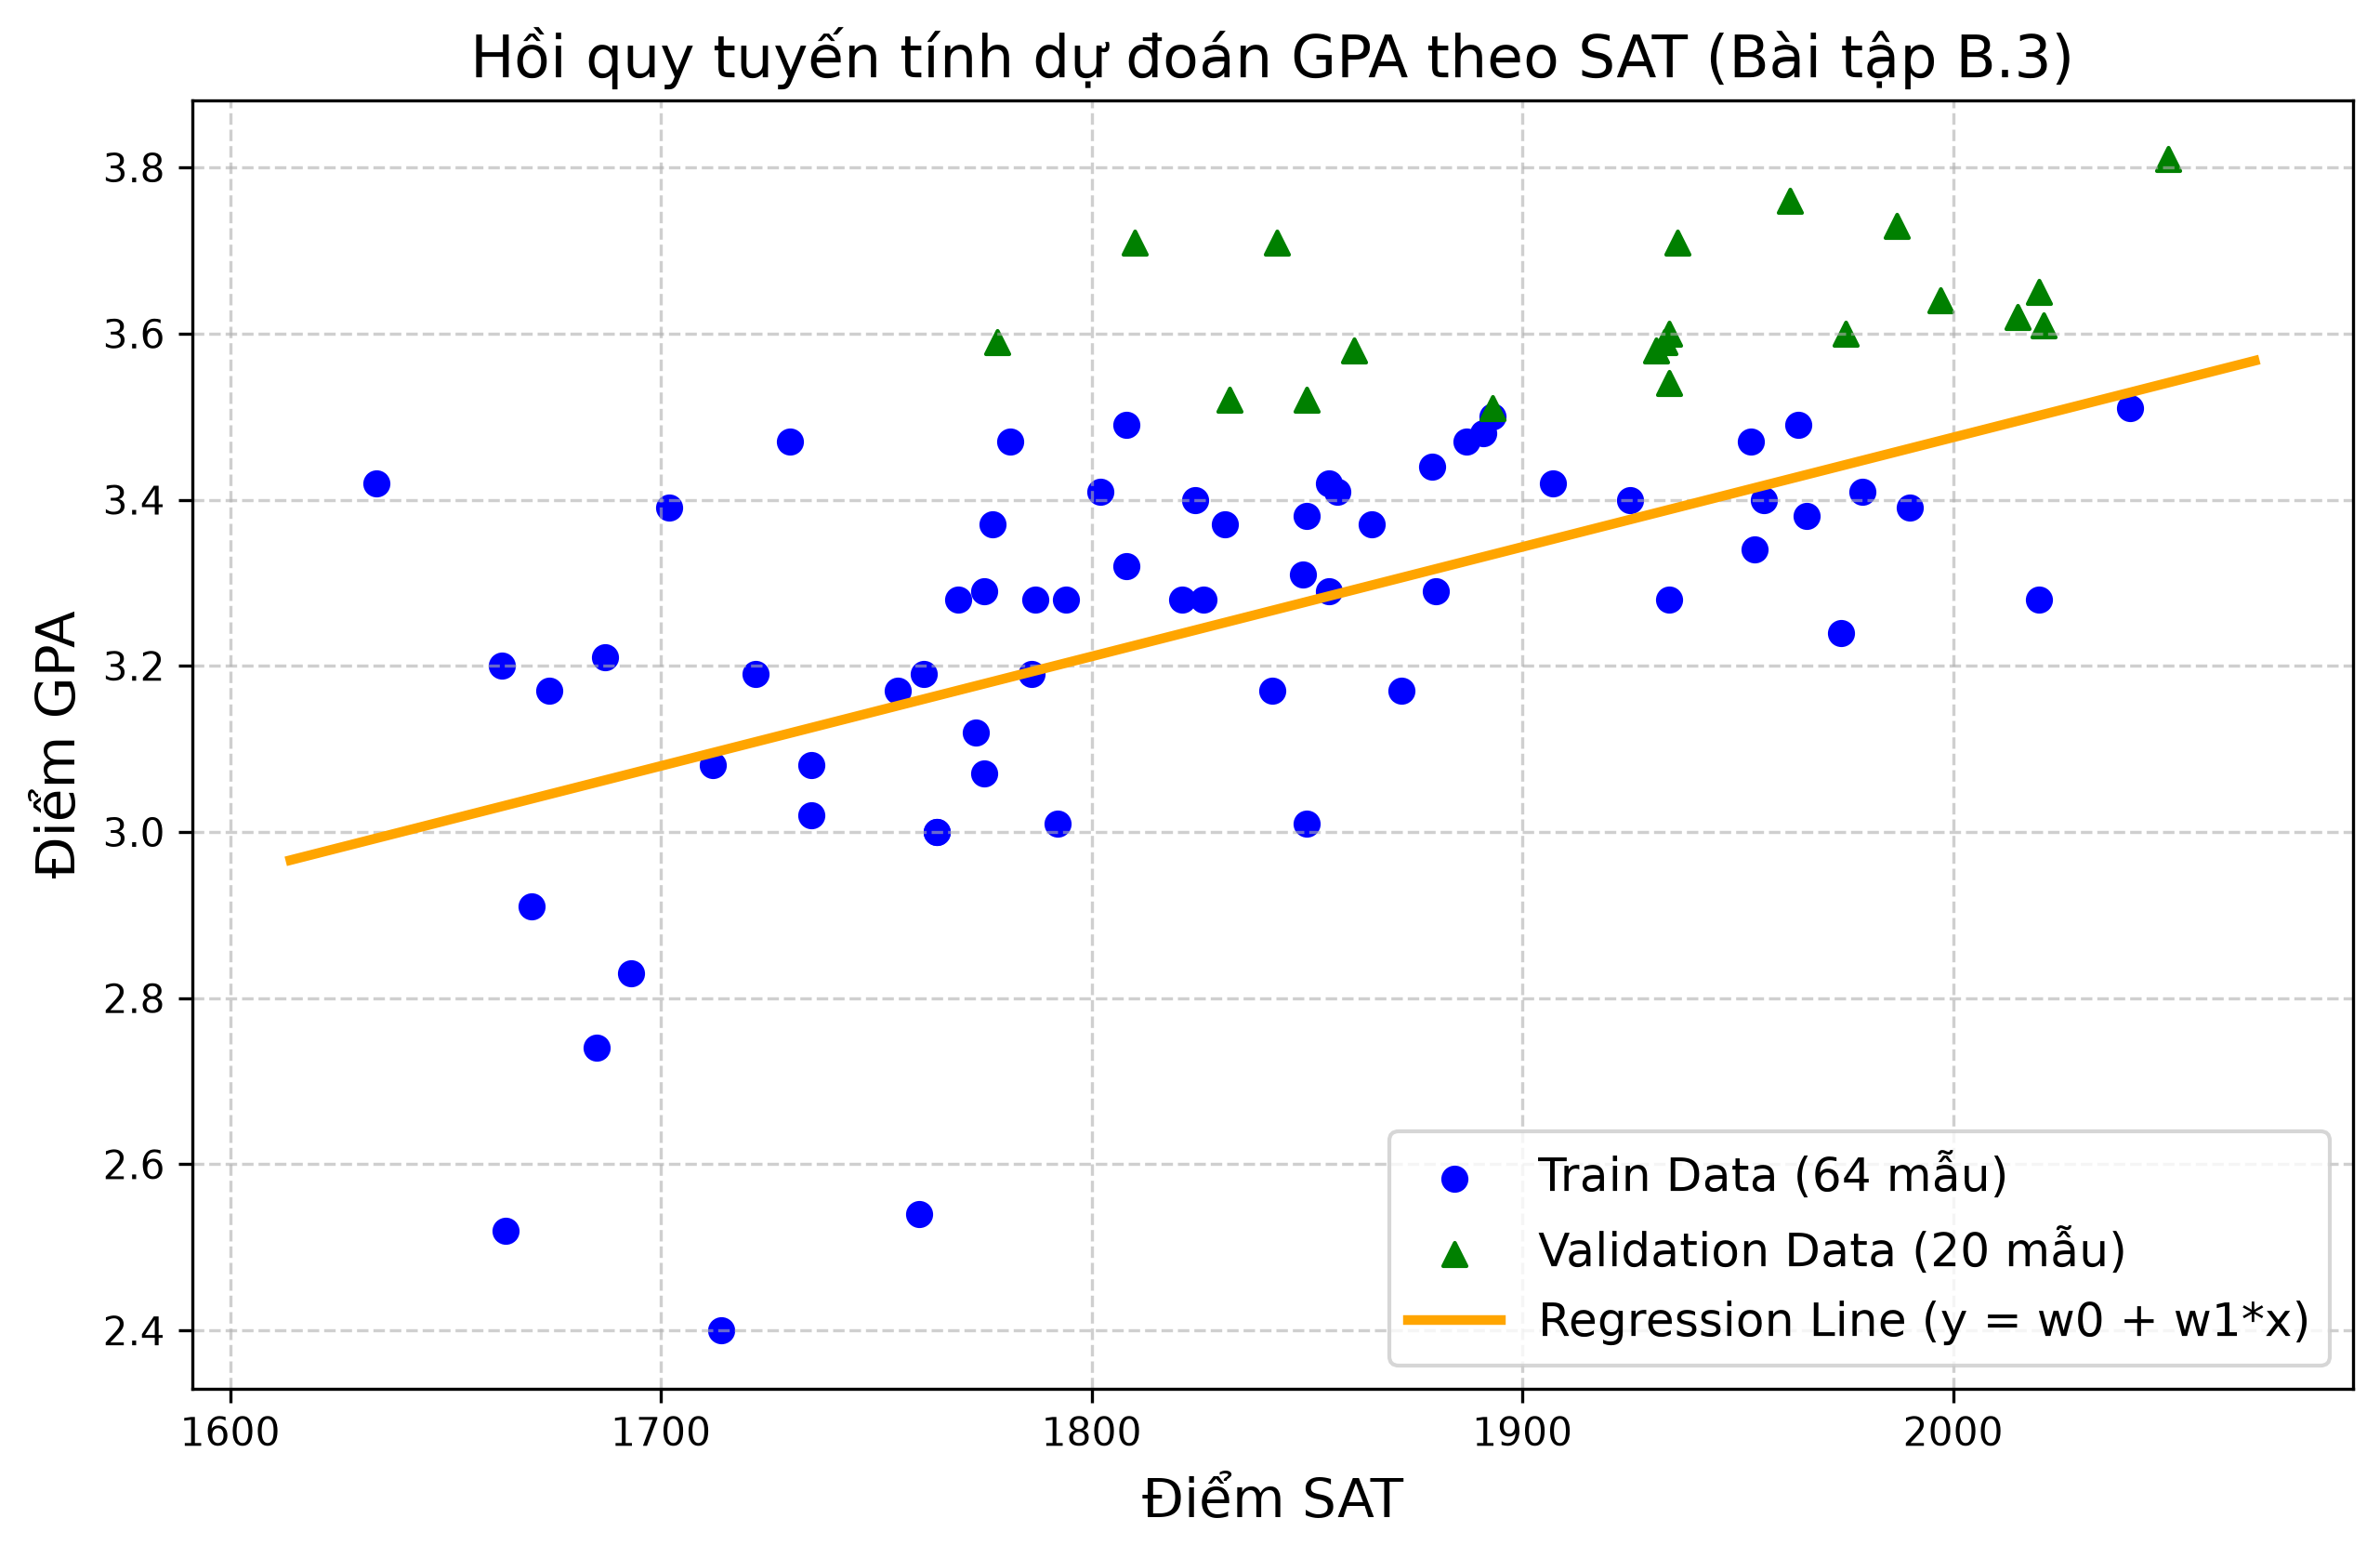

In [ ]:
df_sat = pd.read_csv(os.path.join(GUIDE_DIR, 'SAT_GPA.csv'))
x_sat = df_sat['SAT'].values
y_sat = df_sat['GPA'].values

# (i) Pearson
r_pearson = np.corrcoef(x_sat, y_sat)[0, 1]
print(f'(i) Hệ số tương quan Pearson giữa SAT và GPA: {r_pearson:.5f}')

# (ii) Chia train/val
X_train_sat, y_train_sat = x_sat[:64], y_sat[:64]
X_val_sat, y_val_sat = x_sat[64:], y_sat[64:]

# (iii) Linear Regression
lr_sat = LinearRegression()
lr_sat.fit(X_train_sat.reshape(-1, 1), y_train_sat)
w0_sat, w1_sat = lr_sat.intercept_, lr_sat.coef_[0]
print(f'(iii) Phương trình hồi quy: GPA = {w0_sat:.6f} + {w1_sat:.6f} * SAT')

# Vẽ đồ thị
plt.figure(figsize=(9, 5))
plt.scatter(X_train_sat, y_train_sat, color='blue', label='Train (64 mẫu)')
plt.scatter(X_val_sat, y_val_sat, color='green', marker='^', label='Val (20 mẫu)')
x_vals = np.linspace(min(x_sat)-10, max(x_sat)+10, 100)
plt.plot(x_vals, w0_sat + w1_sat * x_vals, color='orange', lw=2.5, label='Regression Line')
plt.xlabel('Điểm SAT'); plt.ylabel('Điểm GPA'); plt.legend(); plt.grid(True)
plt.title('Hồi quy tuyến tính SAT vs GPA')
plt.show()

# (iv) Đánh giá Linear Regression trên val
pred_lr_sat = lr_sat.predict(X_val_sat.reshape(-1, 1))
mse_lr_sat = mean_squared_error(y_val_sat, pred_lr_sat)
mae_lr_sat = mean_absolute_error(y_val_sat, pred_lr_sat)
r2_lr_sat = r2_score(y_val_sat, pred_lr_sat)

# (v) K-NN (k = 8)
def knn_1d(train_x, train_y, test_x, k=8):
    return np.array([np.mean(train_y[np.argsort(np.abs(train_x - val))[:k]]) for val in test_x])

pred_knn_sat = knn_1d(X_train_sat, y_train_sat, X_val_sat, 8)
mse_knn_sat = mean_squared_error(y_val_sat, pred_knn_sat)
mae_knn_sat = mean_absolute_error(y_val_sat, pred_knn_sat)
r2_knn_sat = r2_score(y_val_sat, pred_knn_sat)

print('(iv & v) So sánh kết quả trên tập Validation:')
print(f'Linear Regression -> MSE: {mse_lr_sat:.6f}, MAE: {mae_lr_sat:.6f}, R2: {r2_lr_sat:.6f}')
print(f'K-NN (k = 8)      -> MSE: {mse_knn_sat:.6f}, MAE: {mae_knn_sat:.6f}, R2: {r2_knn_sat:.6f}')

## 3. BÀI TẬP 2 (VÍ DỤ B.4): Độ dày lớp nội trung mạc (NTM)
- a) Tính hệ số hồi quy trên toàn bộ 100 mẫu.
- b) Huấn luyện trên 80 mẫu đầu, test trên 20 mẫu sau, tính kỳ vọng và phương sai của sai số.

In [4]:
df_ntm = pd.read_csv(os.path.join(GUIDE_DIR, 'vidu4_lin_reg.txt'), sep=r'\s+')
features_ntm = ['TUOI', 'CHOLESTEROL', 'GLUCOSE', 'HA', 'BMI']
X_ntm = df_ntm[features_ntm].values
y_ntm = df_ntm['BEDAYNTM'].values

# a) 100 mẫu
lr_ntm_all = LinearRegression()
lr_ntm_all.fit(X_ntm, y_ntm)
print('a) Hệ số hồi quy trên toàn bộ 100 mẫu:')
print(f' - beta_0 (Intercept): {lr_ntm_all.intercept_:.6f}')
for f, c in zip(features_ntm, lr_ntm_all.coef_):
    print(f' - {f:<15}: {c:.6f}')

# b) 80 train / 20 test
X_tr_ntm, y_tr_ntm = X_ntm[:80], y_ntm[:80]
X_te_ntm, y_te_ntm = X_ntm[80:], y_ntm[80:]

lr_ntm_split = LinearRegression()
lr_ntm_split.fit(X_tr_ntm, y_tr_ntm)
y_te_pred_ntm = lr_ntm_split.predict(X_te_ntm)
errors_ntm = y_te_ntm - y_te_pred_ntm

print('\nb) Đánh giá sai số trên 20 mẫu test:')
print(f' - Kỳ vọng sai số (Mean error)   E[e]   = {np.mean(errors_ntm):.6f}')
print(f' - Phương sai sai số (Var error) Var(e) = {np.var(errors_ntm):.6f}')
print(f' - Độ lệch chuẩn sai số          Std(e) = {np.std(errors_ntm):.6f}')

a) Hệ số hồi quy trên toàn bộ 100 mẫu:
 - beta_0 (Intercept): -0.108029
 - TUOI           : 0.009947
 - CHOLESTEROL    : 0.038470
 - GLUCOSE        : 0.007670
 - HA             : 0.002181
 - BMI            : -0.000207

b) Đánh giá sai số trên 20 mẫu test:
 - Kỳ vọng sai số (Mean error)   E[e]   = 0.079989
 - Phương sai sai số (Var error) Var(e) = 0.221003
 - Độ lệch chuẩn sai số          Std(e) = 0.470109


## 4. BÀI TẬP 3 (VÍ DỤ B.5): Giá bất động sản (`real_estate.csv`)
- 350 mẫu đầu làm train, 64 mẫu sau làm validation.
- Xây dựng Linear Regression (tính RSS).
- Xây dựng K-NN (K = 18, tính RSS).
- So sánh và giải thích.

Tổng bình phương sai số Hồi quy tuyến tính (RSS_LR) : 4228.1469
Tổng bình phương sai số K-NN K=18        (RSS_KNN): 2809.2935


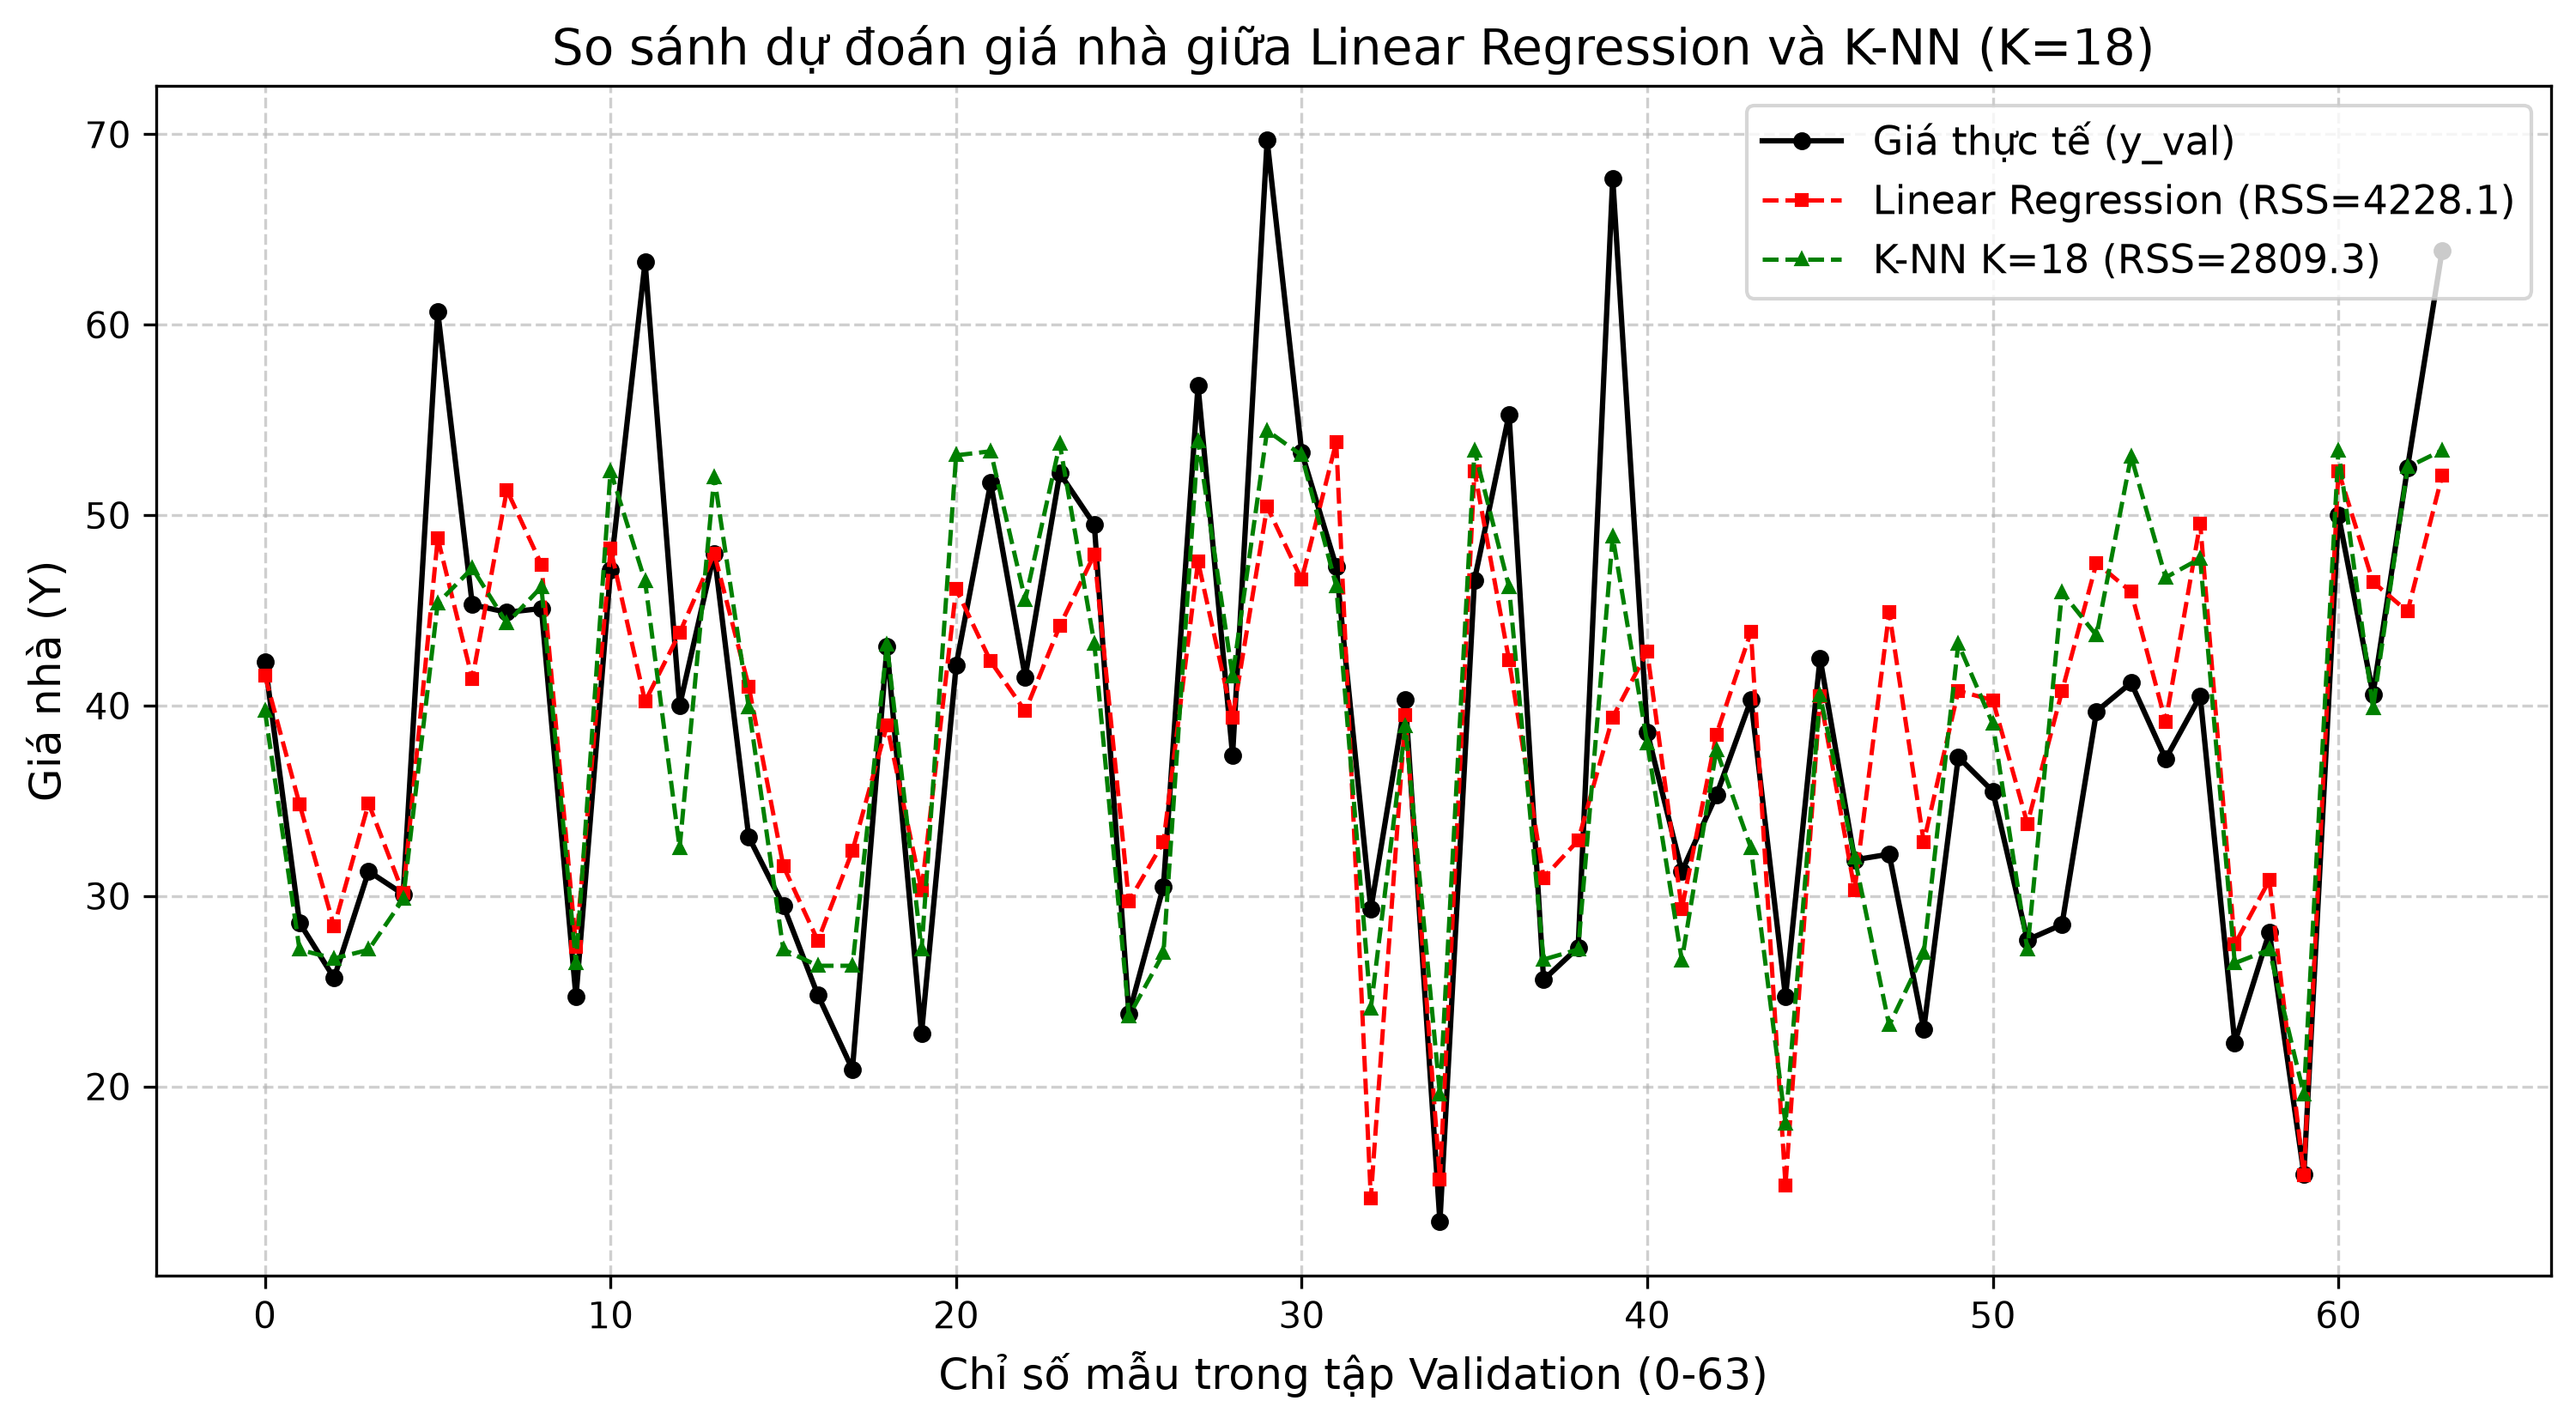

In [5]:
df_re = pd.read_csv(os.path.join(GUIDE_DIR, 'real_estate.csv'))
feat_re = ['X2 house age', 'X3 distance to the nearest MRT station', 'X4 number of convenience stores', 'X5 latitude', 'X6 longitude']
X_re = df_re[feat_re].values
y_re = df_re['Y house price of unit area'].values

X_train_re, y_train_re = X_re[:350], y_re[:350]
X_val_re, y_val_re = X_re[350:], y_re[350:]

# Linear Regression
lr_re = LinearRegression()
lr_re.fit(X_train_re, y_train_re)
pred_lr_re = lr_re.predict(X_val_re)
rss_lr = np.sum((y_val_re - pred_lr_re) ** 2)

# K-NN (K = 18)
def knn_multi(X_train, y_train, X_val, k=18):
    preds = []
    for x in X_val:
        dists = np.linalg.norm(X_train - x, ord=2, axis=1) # axis=1
        idx = np.argsort(dists)[:k]
        preds.append(np.mean(y_train[idx]))
    return np.array(preds)

pred_knn_re = knn_multi(X_train_re, y_train_re, X_val_re, 18)
rss_knn = np.sum((y_val_re - pred_knn_re) ** 2)

print(f'Tổng bình phương sai số Hồi quy tuyến tính (RSS_LR) : {rss_lr:.4f}')
print(f'Tổng bình phương sai số K-NN K=18        (RSS_KNN): {rss_knn:.4f}')

# Vẽ đồ thị so sánh
plt.figure(figsize=(10, 5))
plt.plot(y_val_re, 'k-o', label='Giá thực tế')
plt.plot(pred_lr_re, 'r--s', label=f'Linear Regression (RSS={rss_lr:.1f})')
plt.plot(pred_knn_re, 'g--^', label=f'K-NN K=18 (RSS={rss_knn:.1f})')
plt.xlabel('Mẫu trong Validation (0 - 63)'); plt.ylabel('Giá nhà')
plt.legend(); plt.grid(True)
plt.title('So sánh dự đoán giá nhà giữa Linear Regression và K-NN (K=18)')
plt.show()